In [2]:
!pip install -q git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 79.5 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have nu

Device       : cuda
GPU          : Tesla T4
VRAM         : 15.6 GB
Dataset root : /kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images

Config: {
  "batch_size": 256,
  "num_workers": 2,
  "epochs": 40,
  "lr": 0.0003,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "dropout": 0.3,
  "use_amp": true,
  "seed": 42,
  "clip_model": "ViT-B/32",
  "fft_dim": 256,
  "fusion_dim": 512,
  "img_size": 224,
  "patience": 7,
  "train_frac": 0.7,
  "val_frac": 0.15,
  "test_frac": 0.15
}

Total pooled images: 120,000
  train: 84,000  val: 18,000  test: 18,000
[train] 84,000 images
[val] 18,000 images
[test] 18,000 images


100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 160MiB/s]



Trainable parameters : 52,498,945
CLIP feature dim     : 512

════════════════════════════════════════════════════════════
  CLIP + FFT Detector — Training  (early stopping patience=7)
════════════════════════════════════════════════════════════


Epoch 01 [train]:   0%|          | 0/328 [00:00<?, ?it/s]

[val]:   0%|          | 0/71 [00:00<?, ?it/s]

Ep 01/40 | tr_loss=0.2530 tr_acc=0.8878 | val_loss=0.1603 val_acc=0.9361 AUC=0.9874 F1=0.9340 MCC=0.8739 | 494.3s


... (106 outputs left out)

[val]:   0%|          | 0/71 [00:00<?, ?it/s]

Ep 37/40 | tr_loss=0.0306 tr_acc=0.9882 | val_loss=0.0813 val_acc=0.9744 AUC=0.9967 F1=0.9744 MCC=0.9489 | 239.2s  [no improve 6/7]

⏹  Early stopping triggered at epoch 37 (best VAL AUC = 0.9967)

✓ Best VAL AUC-ROC : 0.9967  (checkpoint → /kaggle/working/checkpoints/clip_fft_best.pt)


[test]:   0%|          | 0/71 [00:00<?, ?it/s]


──────────────────────────────────────────────────
  Final TEST Metrics (best checkpoint, selected on VAL)
──────────────────────────────────────────────────
  loss        : 0.0766
  acc         : 0.9744
  f1          : 0.9743
  precision   : 0.9770
  recall      : 0.9717
  auc_roc     : 0.9971
  ap          : 0.9971
  mcc         : 0.9488


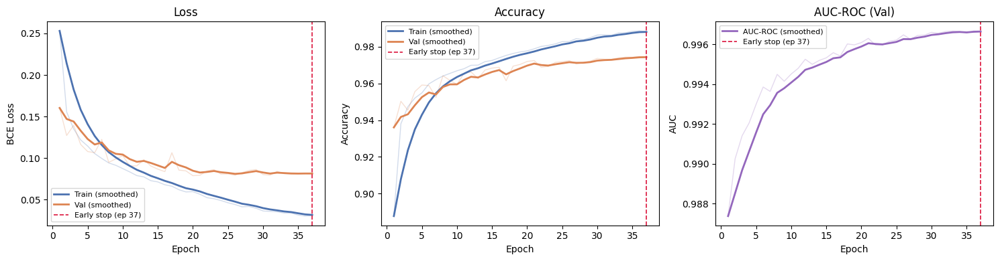

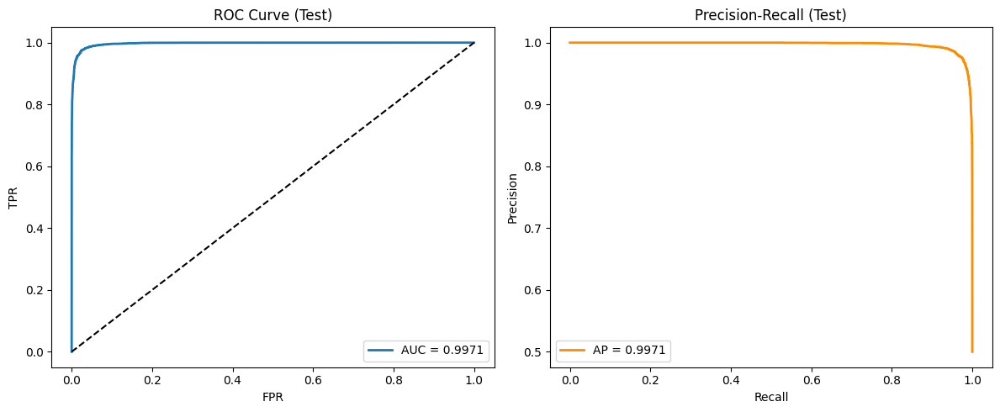

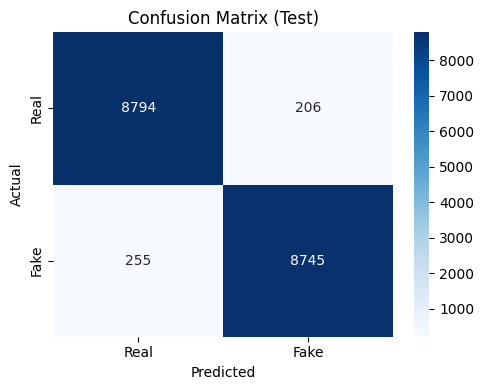

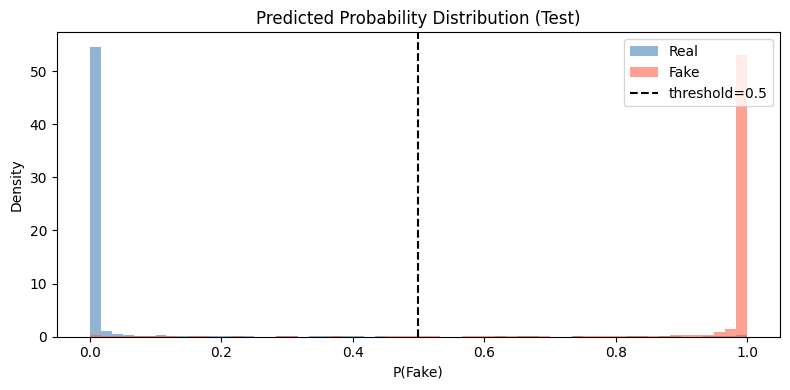


All outputs saved to /kaggle/working/outputs


In [3]:


import os, json, time, warnings, pickle, random
from pathlib import Path
import numpy as np
import numpy._core.multiarray
import numpy.dtypes
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
import matplotlib.patheffects as pe
import seaborn as sns
import torch
import torch.nn as nn
import torch.fft
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    roc_curve, precision_recall_curve, confusion_matrix, auc,
)
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from scipy.stats import gaussian_kde
from tqdm.notebook import tqdm
import clip   # openai/CLIP

warnings.filterwarnings("ignore")

# ── Safe globals for torch.load ───────────────────────────────────────────────
torch.serialization.add_safe_globals([
    numpy._core.multiarray.scalar,
    numpy.dtype,
    numpy.ndarray,
    numpy.float64,
    numpy.float32,
    numpy.int64,
    numpy.int32,
    numpy.bool_,
])
_numpy_dtype_classes = [
    getattr(numpy.dtypes, _name)
    for _name in dir(numpy.dtypes)
    if not _name.startswith("_")
    and isinstance(getattr(numpy.dtypes, _name), type)
]
torch.serialization.add_safe_globals(_numpy_dtype_classes)

# ── Device & Paths ────────────────────────────────────────────────────────────
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATASET_ROOT = Path("/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images")
OUTPUT_DIR   = Path("/kaggle/working/outputs")
CKPT_DIR     = Path("/kaggle/working/checkpoints")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Device       : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")
    print(f"VRAM         : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"Dataset root : {DATASET_ROOT}")

# ── Config ────────────────────────────────────────────────────────────────────
CFG = {
    "batch_size"    : 256,
    "num_workers"   : 2,
    "epochs"        : 40,
    "lr"            : 3e-4,
    "weight_decay"  : 1e-2,
    "grad_clip"     : 1.0,
    "dropout"       : 0.3,
    "use_amp"       : True,
    "seed"          : 42,
    "clip_model"    : "ViT-B/32",
    "fft_dim"       : 256,
    "fusion_dim"    : 512,
    "img_size"      : 224,
    "patience"      : 7,          # early stopping patience
    "train_frac"    : 0.70,
    "val_frac"      : 0.15,
    "test_frac"     : 0.15,
}
CFG["use_amp"] = CFG["use_amp"] and torch.cuda.is_available()
torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])
random.seed(CFG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG["seed"])
print("\nConfig:", json.dumps(CFG, indent=2))


# ══════════════════════════════════════════════════════════════════════════════
# 1.  DATASET  (pooled, then 70/15/15 stratified split)
# ══════════════════════════════════════════════════════════════════════════════
def collect_samples(root: Path):
    """
    Pools images from BOTH CIFAKE folders (train/ and test/) into one list,
    so the 70/15/15 split below controls the actual proportions used —
    CIFAKE's own train/test split is ignored.
    """
    samples = []
    for split in ("train", "test"):
        for label_name, label in [("REAL", 0), ("FAKE", 1)]:
            folder = root / split / label_name
            if not folder.exists():
                raise FileNotFoundError(f"Folder not found: {folder}")
            for p in sorted(folder.iterdir()):
                if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                    samples.append((p, label))
    return samples


class CIFAKEDataset(Dataset):
    """Thin wrapper around a pre-built list of (path, label) samples."""
    def __init__(self, samples, transform=None, name="split"):
        self.samples   = samples
        self.transform = transform
        print(f"[{name}] {len(self.samples):,} images")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


all_samples = collect_samples(DATASET_ROOT)
all_paths   = [s[0] for s in all_samples]
all_labels  = [s[1] for s in all_samples]
print(f"\nTotal pooled images: {len(all_samples):,}")

# Step 1: split off train (70%) vs rest (30%)
train_samples, rest_samples = train_test_split(
    all_samples,
    train_size=CFG["train_frac"],
    stratify=all_labels,
    random_state=CFG["seed"],
)
# Step 2: split rest (30%) into val (15%) / test (15%)  -> 50/50 of "rest"
rest_labels = [s[1] for s in rest_samples]
val_share_of_rest = CFG["val_frac"] / (CFG["val_frac"] + CFG["test_frac"])  # 0.5
val_samples, test_samples = train_test_split(
    rest_samples,
    train_size=val_share_of_rest,
    stratify=rest_labels,
    random_state=CFG["seed"],
)
print(f"  train: {len(train_samples):,}  "
      f"val: {len(val_samples):,}  test: {len(test_samples):,}")

# CLIP standard normalisation (matches clip.load preprocessing)
CLIP_MEAN = (0.48145466, 0.4578275,  0.40821073)
CLIP_STD  = (0.26862954, 0.26130258, 0.27577711)

train_tf = transforms.Compose([
    transforms.Resize((CFG["img_size"], CFG["img_size"])),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(CLIP_MEAN, CLIP_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((CFG["img_size"], CFG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(CLIP_MEAN, CLIP_STD),
])

train_ds = CIFAKEDataset(train_samples, train_tf, "train")
val_ds   = CIFAKEDataset(val_samples,   eval_tf,  "val")
test_ds  = CIFAKEDataset(test_samples,  eval_tf,  "test")

train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"],
                          shuffle=True,  num_workers=CFG["num_workers"],
                          pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=CFG["batch_size"],
                          shuffle=False, num_workers=CFG["num_workers"],
                          pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=CFG["batch_size"],
                          shuffle=False, num_workers=CFG["num_workers"],
                          pin_memory=True)


# ══════════════════════════════════════════════════════════════════════════════
# 2.  MODEL COMPONENTS
# ══════════════════════════════════════════════════════════════════════════════

# ── 2a. FFT Feature Extractor ─────────────────────────────────────────────────
class FFTFeatureExtractor(nn.Module):
    """
    Extracts frequency-domain features from a batch of images.

    Steps:
      1. Convert to grayscale (channel average).
      2. Apply 2-D FFT → take log-magnitude spectrum.
      3. Flatten & project through a small MLP → fixed-dim representation.

    AI-generated images show characteristic artefacts in the frequency
    domain (grid patterns, missing high-frequency detail) that complement
    the semantic features from CLIP.
    """
    def __init__(self, img_size: int = 224, out_dim: int = 256, dropout: float = 0.3):
        super().__init__()
        freq_flat = img_size * img_size
        self.mlp = nn.Sequential(
            nn.Linear(freq_flat, 1024),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(1024, out_dim),
            nn.LayerNorm(out_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        gray = x.mean(dim=1)
        fft  = torch.fft.fft2(gray)
        mag  = torch.log(torch.abs(fft) + 1e-6)
        mag  = mag.reshape(mag.size(0), -1)
        return self.mlp(mag)


# ── 2b. CLIP Image Encoder (real OpenAI CLIP, frozen backbone) ───────────────
class CLIPEncoder(nn.Module):
    """
    Real OpenAI CLIP visual encoder (frozen).
    ViT-B/32 -> 512-d image embedding. ViT-B/16 / ViT-L/14 also supported
    via CFG["clip_model"]; out_dim is read directly from the loaded model.
    """
    def __init__(self, model_name: str = "ViT-B/32", device=DEVICE):
        super().__init__()
        clip_model, _ = clip.load(model_name, device=device, jit=False)
        self.visual = clip_model.visual.float()   # use fp32 for stable AMP autocast
        for p in self.visual.parameters():
            p.requires_grad_(False)
        self.visual.eval()
        # infer output dim from the projection layer
        self.out_dim = clip_model.visual.output_dim

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x is already normalised with CLIP_MEAN/STD and resized to img_size
        return self.visual(x)


# ── 2c. Feature Fusion ────────────────────────────────────────────────────────
class GatedFusion(nn.Module):
    """
    Learned gated fusion:
        gate  = sigmoid(W_g [clip_feat || fft_feat])
        fused = gate * proj_clip + (1 - gate) * proj_fft

    Lets the model weight semantic vs. frequency evidence per sample.
    """
    def __init__(self, clip_dim: int, fft_dim: int, out_dim: int, dropout: float = 0.3):
        super().__init__()
        self.proj_clip = nn.Sequential(nn.Linear(clip_dim, out_dim), nn.GELU())
        self.proj_fft  = nn.Sequential(nn.Linear(fft_dim,  out_dim), nn.GELU())
        self.gate      = nn.Linear(clip_dim + fft_dim, out_dim)
        self.norm      = nn.LayerNorm(out_dim)
        self.drop      = nn.Dropout(dropout)

    def forward(self, clip_feat: torch.Tensor, fft_feat: torch.Tensor) -> torch.Tensor:
        pc = self.proj_clip(clip_feat)
        pf = self.proj_fft(fft_feat)
        g  = torch.sigmoid(self.gate(torch.cat([clip_feat, fft_feat], dim=-1)))
        fused = g * pc + (1 - g) * pf
        return self.drop(self.norm(fused))


# ── 2d. Full Model ─────────────────────────────────────────────────────────────
class CLIPFFTDetector(nn.Module):
    """
    Full pipeline:
        Image → CLIP encoder  → clip_feat (512 for ViT-B/32)
             → FFT extractor  → fft_feat  (256)
             → GatedFusion    → fused     (512)
             → Classifier     → logit     (1)
    """
    def __init__(self, cfg: dict, device=DEVICE):
        super().__init__()
        self.clip_enc = CLIPEncoder(cfg["clip_model"], device=device)
        clip_dim = self.clip_enc.out_dim

        self.fft_enc = FFTFeatureExtractor(
            img_size=cfg["img_size"],
            out_dim=cfg["fft_dim"],
            dropout=cfg["dropout"],
        )

        self.fusion = GatedFusion(
            clip_dim=clip_dim,
            fft_dim=cfg["fft_dim"],
            out_dim=cfg["fusion_dim"],
            dropout=cfg["dropout"],
        )

        self.classifier = nn.Sequential(
            nn.Linear(cfg["fusion_dim"], 128),
            nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(128, 1),
        )

    def forward(self, x: torch.Tensor):
        clip_feat = self.clip_enc(x).float()
        fft_feat  = self.fft_enc(x)
        fused     = self.fusion(clip_feat, fft_feat)
        logit     = self.classifier(fused)
        return logit.squeeze(1)


model = CLIPFFTDetector(CFG, DEVICE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters : {n_params:,}")
print(f"CLIP feature dim     : {model.clip_enc.out_dim}")


# ══════════════════════════════════════════════════════════════════════════════
# 3.  TRAINING UTILITIES
# ══════════════════════════════════════════════════════════════════════════════
criterion = nn.BCEWithLogitsLoss()
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CFG["lr"],
    weight_decay=CFG["weight_decay"],
)
scheduler = CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
scaler    = GradScaler(enabled=CFG["use_amp"])


def train_one_epoch(model, loader, optimizer, scaler, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc=f"Epoch {epoch:02d} [train]", leave=False)
    for imgs, labels in pbar:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.float().to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=CFG["use_amp"]):
            logits = model(imgs)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        preds       = (torch.sigmoid(logits) > 0.5).long()
        correct    += (preds == labels.long()).sum().item()
        total      += labels.size(0)
        total_loss += loss.item() * labels.size(0)
        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{correct/total:.4f}")
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, split="val"):
    model.eval()
    all_logits, all_labels = [], []
    for imgs, labels in tqdm(loader, desc=f"[{split}]", leave=False):
        imgs = imgs.to(DEVICE, non_blocking=True)
        with autocast(enabled=CFG["use_amp"]):
            logits = model(imgs)
        all_logits.append(logits.float().cpu())
        all_labels.append(labels)
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy()
    probs  = 1 / (1 + np.exp(-logits))
    preds  = (probs > 0.5).astype(int)
    return {
        "loss"     : float(criterion(torch.tensor(logits), torch.tensor(labels, dtype=torch.float32))),
        "acc"      : accuracy_score(labels, preds),
        "f1"       : f1_score(labels, preds, zero_division=0),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall"   : recall_score(labels, preds, zero_division=0),
        "auc_roc"  : roc_auc_score(labels, probs),
        "ap"       : average_precision_score(labels, probs),
        "mcc"      : matthews_corrcoef(labels, preds),
        "probs"    : probs,
        "labels"   : labels,
        "preds"    : preds,
    }


# ── Early Stopping ────────────────────────────────────────────────────────────
class EarlyStopping:
    """Stops training when monitored metric doesn't improve for `patience` epochs."""
    def __init__(self, patience: int = 7, min_delta: float = 1e-4, mode: str = "max"):
        self.patience   = patience
        self.min_delta  = min_delta
        self.mode       = mode
        self.best       = float("-inf") if mode == "max" else float("inf")
        self.counter    = 0
        self.stop       = False

    def step(self, value: float) -> bool:
        improved = (value - self.best > self.min_delta) if self.mode == "max" \
                   else (self.best - value > self.min_delta)
        if improved:
            self.best    = value
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return self.stop


# ── Smoothing helper ──────────────────────────────────────────────────────────
def smooth(values, weight: float = 0.6):
    """Exponential moving average smoothing for plot curves."""
    smoothed, last = [], values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        smoothed.append(last)
    return smoothed


# ══════════════════════════════════════════════════════════════════════════════
# 4.  TRAINING LOOP  (model-selection on VAL, not TEST)
# ══════════════════════════════════════════════════════════════════════════════
history = {"train_loss": [], "train_acc": [],
           "val_loss":  [], "val_acc":  [], "val_auc": []}
best_auc      = 0.0
best_ckpt     = CKPT_DIR / "clip_fft_best.pt"
early_stopper = EarlyStopping(patience=CFG["patience"], mode="max")

print("\n" + "═"*60)
print("  CLIP + FFT Detector — Training  (early stopping patience=7)")
print("═"*60)

stopped_epoch = CFG["epochs"]
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler, epoch)
    scheduler.step()
    metrics = evaluate(model, val_loader, "val")   # <-- model selection on VAL

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(metrics["loss"])
    history["val_acc"].append(metrics["acc"])
    history["val_auc"].append(metrics["auc_roc"])

    if metrics["auc_roc"] > best_auc:
        best_auc = metrics["auc_roc"]
        torch.save({"epoch": epoch, "state_dict": model.state_dict(),
                    "metrics": metrics}, best_ckpt)

    elapsed = time.time() - t0
    es_tag  = f"  [no improve {early_stopper.counter}/{CFG['patience']}]" \
              if early_stopper.counter > 0 else ""
    print(f"Ep {epoch:02d}/{CFG['epochs']} | "
          f"tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
          f"val_loss={metrics['loss']:.4f} val_acc={metrics['acc']:.4f} "
          f"AUC={metrics['auc_roc']:.4f} F1={metrics['f1']:.4f} "
          f"MCC={metrics['mcc']:.4f} | {elapsed:.1f}s{es_tag}")

    if early_stopper.step(metrics["auc_roc"]):
        stopped_epoch = epoch
        print(f"\n⏹  Early stopping triggered at epoch {epoch} "
              f"(best VAL AUC = {best_auc:.4f})")
        break

print(f"\n✓ Best VAL AUC-ROC : {best_auc:.4f}  (checkpoint → {best_ckpt})")


# ══════════════════════════════════════════════════════════════════════════════
# 5.  FINAL EVALUATION ON BEST CHECKPOINT — TEST SET (touched once)
# ══════════════════════════════════════════════════════════════════════════════
ckpt = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["state_dict"])
final = evaluate(model, test_loader, "test")

print("\n" + "─"*50)
print("  Final TEST Metrics (best checkpoint, selected on VAL)")
print("─"*50)
for k, v in final.items():
    if k not in ("probs", "labels", "preds"):
        print(f"  {k:<12}: {v:.4f}")


# ══════════════════════════════════════════════════════════════════════════════
# 6.  VISUALISATIONS
# ══════════════════════════════════════════════════════════════════════════════
epochs_x = list(range(1, len(history["train_loss"]) + 1))

# ── 6a. Training curves (raw + smoothed) ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, raw_tr, raw_te, ylabel, title in [
    (axes[0], history["train_loss"], history["val_loss"],  "BCE Loss",   "Loss"),
    (axes[1], history["train_acc"],  history["val_acc"],   "Accuracy",   "Accuracy"),
]:
    # Raw (faded)
    ax.plot(epochs_x, raw_tr, color="#4C72B0", alpha=0.25, linewidth=1)
    ax.plot(epochs_x, raw_te, color="#DD8452", alpha=0.25, linewidth=1)
    # Smoothed
    ax.plot(epochs_x, smooth(raw_tr), color="#4C72B0", linewidth=2,
            label="Train (smoothed)")
    ax.plot(epochs_x, smooth(raw_te), color="#DD8452", linewidth=2,
            label="Val (smoothed)")
    if stopped_epoch < CFG["epochs"]:
        ax.axvline(stopped_epoch, color="crimson", linestyle="--",
                   linewidth=1.2, label=f"Early stop (ep {stopped_epoch})")
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.legend(fontsize=8)

# AUC-ROC
raw_auc = history["val_auc"]
axes[2].plot(epochs_x, raw_auc, color="#9467BD", alpha=0.25, linewidth=1)
axes[2].plot(epochs_x, smooth(raw_auc), color="#9467BD", linewidth=2,
             label="AUC-ROC (smoothed)")
if stopped_epoch < CFG["epochs"]:
    axes[2].axvline(stopped_epoch, color="crimson", linestyle="--",
                    linewidth=1.2, label=f"Early stop (ep {stopped_epoch})")
axes[2].set(title="AUC-ROC (Val)", xlabel="Epoch", ylabel="AUC")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 6b. ROC + PR curves (TEST) ────────────────────────────────────────────────
fpr, tpr, _ = roc_curve(final["labels"], final["probs"])
prec, rec, _ = precision_recall_curve(final["labels"], final["probs"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {final['auc_roc']:.4f}")
axes[0].plot([0,1],[0,1],"k--")
axes[0].set(title="ROC Curve (Test)", xlabel="FPR", ylabel="TPR")
axes[0].legend()

axes[1].plot(rec, prec, lw=2, color="darkorange", label=f"AP = {final['ap']:.4f}")
axes[1].set(title="Precision-Recall (Test)", xlabel="Recall", ylabel="Precision")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 6c. Confusion matrix (TEST) ───────────────────────────────────────────────
cm_arr = confusion_matrix(final["labels"], final["preds"])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_arr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real","Fake"], yticklabels=["Real","Fake"], ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual", title="Confusion Matrix (Test)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 6d. Score distributions (TEST) ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
for lbl, color, name in [(0, "steelblue", "Real"), (1, "tomato", "Fake")]:
    scores = final["probs"][final["labels"] == lbl]
    ax.hist(scores, bins=60, alpha=0.6, color=color, label=name, density=True)
ax.axvline(0.5, color="black", linestyle="--", label="threshold=0.5")
ax.set(title="Predicted Probability Distribution (Test)", xlabel="P(Fake)", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nAll outputs saved to {OUTPUT_DIR}")

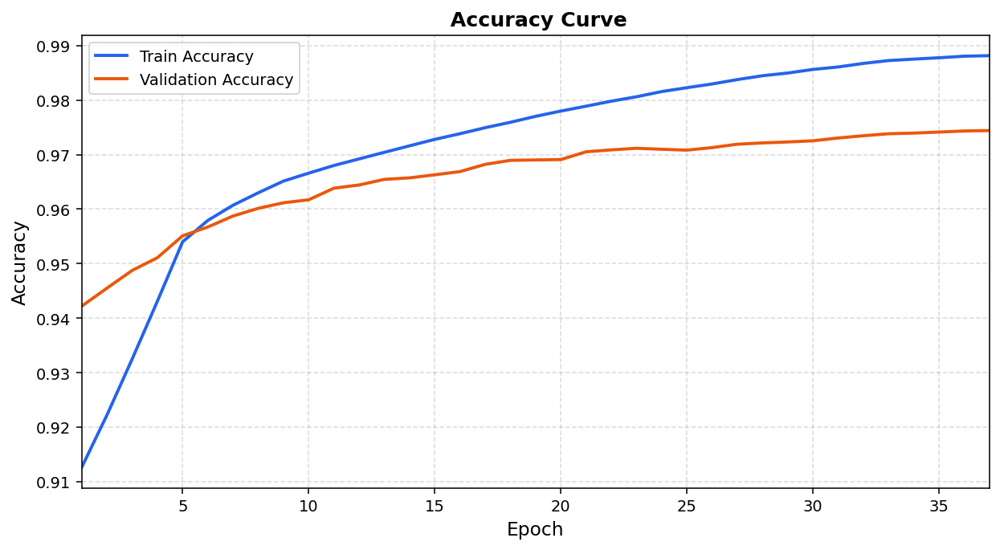

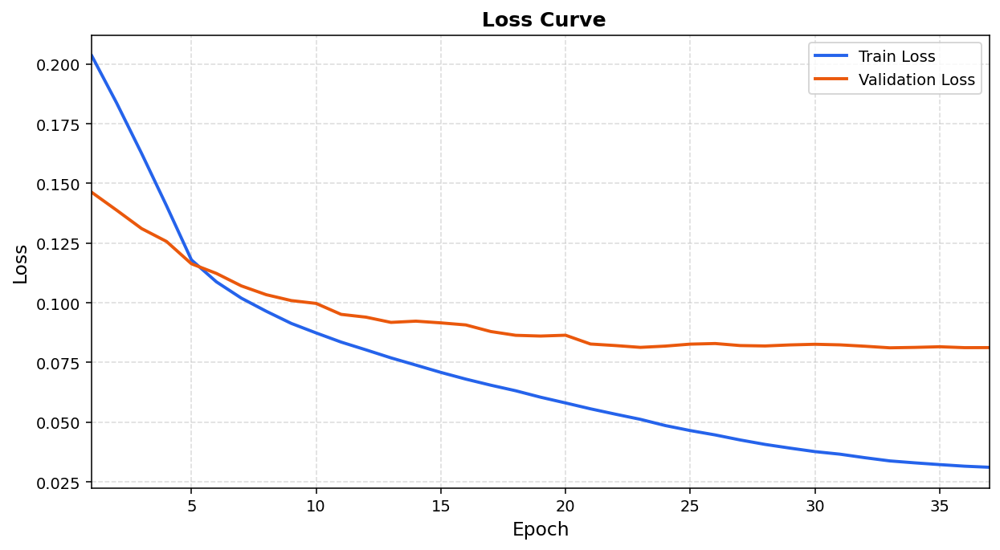

In [4]:
# =============================================================================
#  SMOOTH CURVES ONLY  — no raw lines, no shading
# =============================================================================
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

def smooth(values, window=7):
    arr = np.array(values, dtype=np.float32)
    return uniform_filter1d(arr, size=window, mode="nearest")

epochs = list(range(1, len(history["train_acc"]) + 1))

# ── Accuracy ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), dpi=140)

ax.plot(epochs, smooth(history["train_acc"]), color="#2563EB", lw=2, label="Train Accuracy")
ax.plot(epochs, smooth(history["val_acc"]),   color="#EA580C", lw=2, label="Validation Accuracy")

ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title(" Accuracy Curve", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, linestyle="--", alpha=0.45)
ax.set_xlim(1, epochs[-1])
plt.tight_layout()
plt.show()

# ── Loss ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), dpi=140)

ax.plot(epochs, smooth(history["train_loss"]), color="#2563EB", lw=2, label="Train Loss")
ax.plot(epochs, smooth(history["val_loss"]),   color="#EA580C", lw=2, label="Validation Loss")

ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title(" Loss Curve", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, linestyle="--", alpha=0.45)
ax.set_xlim(1, epochs[-1])
plt.tight_layout()
plt.show()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 1 : Super-Resolution  (32×32 → 512×512)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ✓ SwinIR weights already present
Loading SwinIR-L model...
  ✓ SwinIR-L ready
  Input : (32, 32)
  Pass 1 done : (128, 128)
  Pass 2 done : (512, 512)
  ✓ SR image saved → /kaggle/working/sr_temp/sr_512.png


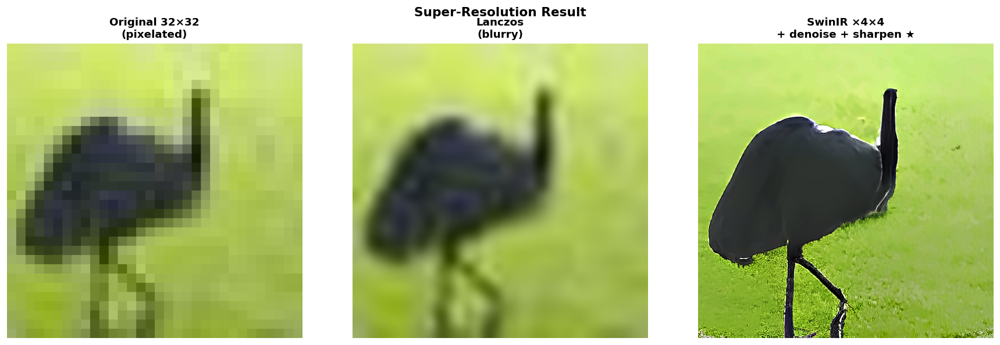


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STEP 2 : XAI  — Grad-CAM, Score-CAM, Layer-CAM, SHAP, Grad-CAM++
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ✓ Auto-selected target layers from spatial_bb:
      layer_main : Conv2d  out_channels=512  spatial=4×4  (deepest)
      layer_aux  : Conv2d  out_channels=256  spatial=8×8   (coarser, for Grad-CAM++ fusion)

  Prediction : FAKE  (p_fake = 0.9238)

  ℹ Class-discriminative target = 'FAKE' (maximize the FAKE logit/score)



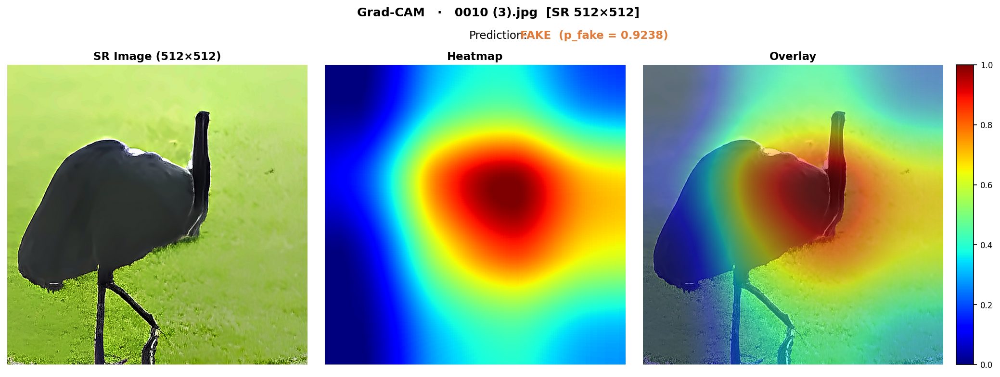

  ✓ Grad-CAM done


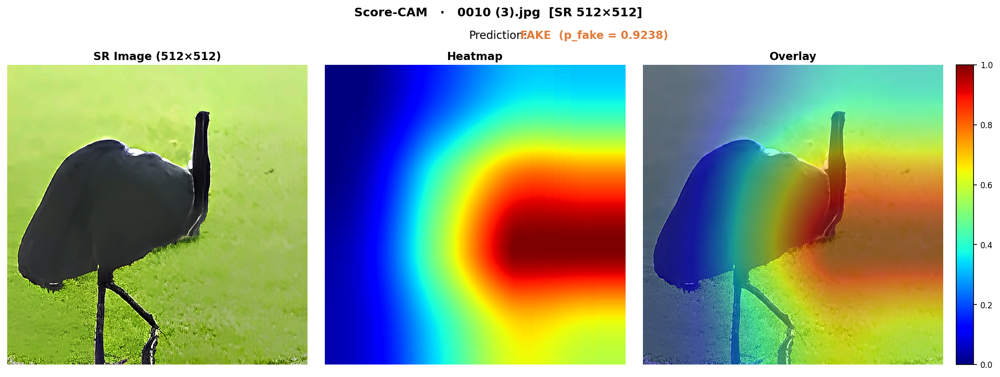

  ✓ Score-CAM done


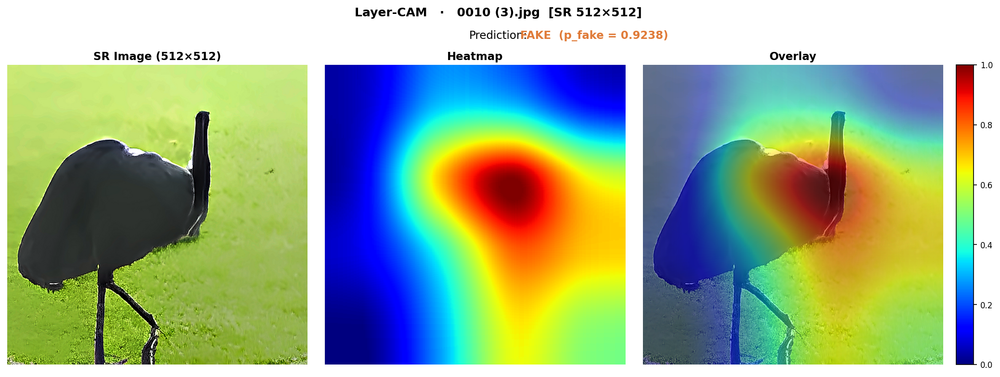

  ✓ Layer-CAM done


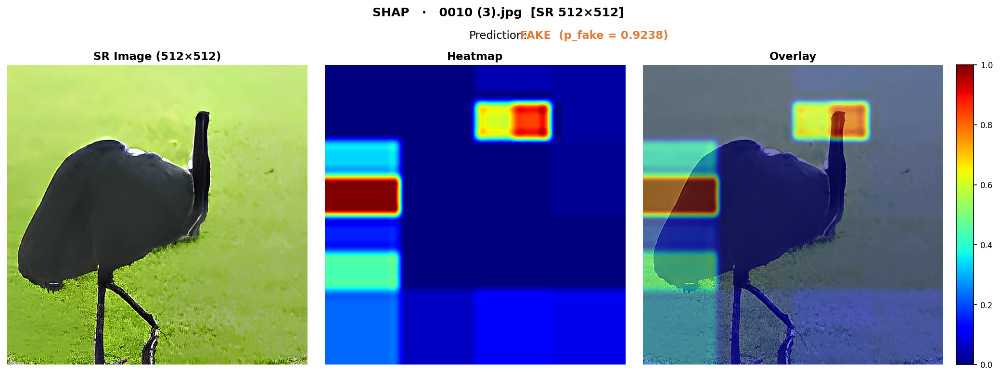

  ✓ SHAP done


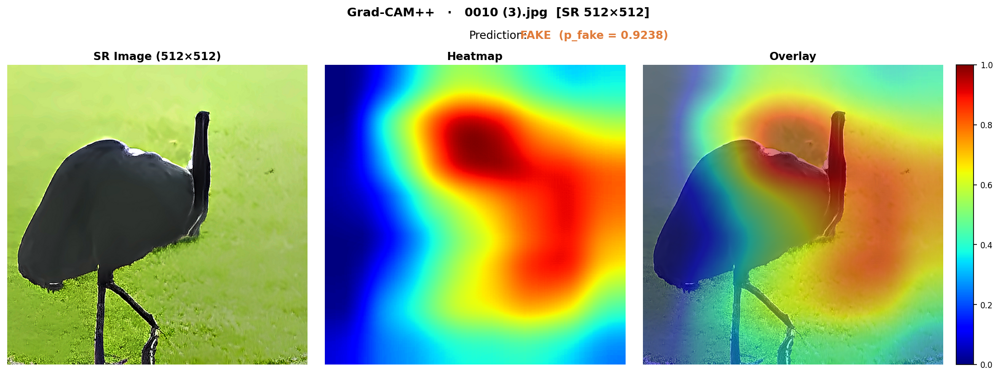

  ✓ Grad-CAM++ done

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ✓ All done — SR + 5 XAI panels displayed inline
     (Grad-CAM, Score-CAM, Layer-CAM, SHAP, Grad-CAM++)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


In [24]:
# =============================================================================
#  CELL 2 — SR + XAI  (Grad-CAM, Score-CAM, Layer-CAM, SHAP, Grad-CAM++)
#  Step 1 : SwinIR 32×32 → 512×512 (two-pass)
#  Step 2 : 5 XAI panels, all class-discriminative toward the PREDICTED label
#
#  NOTES
#  ------------------------------------------------------------------
#  - Gradient-based methods (Grad-CAM, Layer-CAM, Grad-CAM++) backprop on
#    the raw logit, SIGNED toward the model's predicted class (REAL/FAKE)
#    instead of always targeting "fake evidence". Always targeting fake
#    evidence makes Grad-CAM collapse to an all-zero map whenever the
#    model is confidently REAL (every gradient pushes the fake score down
#    → ReLU(Σ weight·activation) clips the whole map to zero).
#  - Score-CAM signs its per-channel score deltas the same way, so all
#    panels agree on what they're explaining.
#  - SHAP uses the model-agnostic Partition explainer (no gradients, no
#    layer hooks at all) — it treats the model as a black box and
#    perturbs/masks the input image directly, so it's immune to the
#    vanishing-gradient failure mode entirely. Its raw output is also
#    signed toward the predicted class for consistency with the rest.
#  - Every CAM has a `_safe_positive` / `_safe_positive_np` fallback: if
#    ReLU ever clips a map to all-zero, it automatically falls back to
#    abs() so no panel can render as a dead flat color again.
# =============================================================================
%matplotlib inline

import os, sys, urllib.request, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import autocast
from torchvision import transforms
from PIL import Image, ImageFilter, ImageEnhance
import cv2

warnings.filterwarnings("ignore")

# ── Device / CFG (must match training cell) ───────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG = {
    "use_amp" : True,
    "img_size": 32,
    "mean"    : [0.5, 0.5, 0.5],
    "std"     : [0.5, 0.5, 0.5],
}

# ── Paths ─────────────────────────────────────────────────────────────────────
ORIG_PATH  = Path("/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test/REAL/0010 (3).jpg")
SR_OUT_DIR = Path("/kaggle/working/sr_temp")
SR_OUT_DIR.mkdir(parents=True, exist_ok=True)
SR_SAVE    = SR_OUT_DIR / "sr_512.png"
FNAME      = ORIG_PATH.name

# =============================================================================
# ░░░ SELF-CONTAINED UTILITIES ░░░
# =============================================================================
_MEAN = torch.tensor(CFG["mean"]).view(1, 3, 1, 1)
_STD  = torch.tensor(CFG["std"]).view(1, 3, 1, 1)

spatial_norm_util = transforms.Normalize(mean=CFG["mean"], std=CFG["std"])

def _denorm(t: torch.Tensor) -> torch.Tensor:
    return (t * _STD.to(t.device) + _MEAN.to(t.device)).clamp(0.0, 1.0)

def compute_log_fft_magnitude(pil_img, size=32):
    gray = pil_img.convert("L").resize((size, size), Image.LANCZOS)
    arr  = np.array(gray, dtype=np.float32) / 255.0
    fft  = np.fft.fftshift(np.fft.fft2(arr))
    mag  = np.log1p(np.abs(fft)).astype(np.float32)
    mag  = (mag - mag.min()) / (mag.max() - mag.min() + 1e-8)
    return torch.from_numpy(mag).unsqueeze(0)   # (1, H, W)

def _build_full_batch(pil_img, device):
    """
    Build ALL keys the model forward() needs.

      batch["spatial"]  → spatial_bb   : normalised RGB (3-ch)
      batch["spectral"] → spec_branch  : normalised RGB (3-ch)  ← HPF expects 3 channels
      batch["raw"]      → recon_branch : un-normalised RGB [0,1] (3-ch)

    The spec_branch applies its own learned HPF internally, so we just
    pass the same normalised RGB tensor as "spectral" — identical to
    what the training DataLoader did.
    """
    sz  = CFG["img_size"]
    pil = pil_img.resize((sz, sz), Image.LANCZOS)

    # (3, H, W) float in [0, 1]
    rgb_01  = transforms.ToTensor()(pil)

    # normalised spatial input  (1, 3, H, W)
    sp_norm = spatial_norm_util(rgb_01).unsqueeze(0).to(device)

    # raw un-normalised input for recon branch  (1, 3, H, W)
    raw = rgb_01.unsqueeze(0).to(device)

    return {
        "spatial"  : sp_norm,   # (1, 3, H, W)  normalised RGB
        "spectral" : sp_norm,   # (1, 3, H, W)  same — HPF is inside spec_branch
        "raw"      : raw,       # (1, 3, H, W)  un-normalised [0,1]
    }

def load_batch_from_orig(path_or_pil, device=None):
    if device is None:
        device = DEVICE
    pil = (Image.open(path_or_pil).convert("RGB")
           if isinstance(path_or_pil, (str, Path))
           else path_or_pil.convert("RGB"))
    return _build_full_batch(pil, device)

# =============================================================================
# ░░░ STEP 1 — SUPER RESOLUTION ░░░
# =============================================================================
print("━"*60)
print("  STEP 1 : Super-Resolution  (32×32 → 512×512)")
print("━"*60)

os.system("pip install timm einops shap -q")
SWINIR_DIR = Path("/kaggle/working/SwinIR")
if not SWINIR_DIR.exists():
    os.system("git clone https://github.com/JingyunLiang/SwinIR.git /kaggle/working/SwinIR -q")
if str(SWINIR_DIR) not in sys.path:
    sys.path.insert(0, str(SWINIR_DIR))

from models.network_swinir import SwinIR as _SwinIR

SWINIR_CKPT = Path("/kaggle/working/swinir_realsr_x4.pth")
if not SWINIR_CKPT.exists():
    print("Downloading SwinIR weights (~136 MB)...")
    urllib.request.urlretrieve(
        "https://github.com/JingyunLiang/SwinIR/releases/download/v0.0/"
        "003_realSR_BSRGAN_DFOWMFC_s64w8_SwinIR-L_x4_GAN.pth",
        SWINIR_CKPT)
    print("  ✓ Downloaded")
else:
    print("  ✓ SwinIR weights already present")

def _build_swinir(device):
    m = _SwinIR(
        upscale=4, in_chans=3, img_size=64, window_size=8, img_range=1.0,
        depths=[6]*9, embed_dim=240, num_heads=[8]*9,
        mlp_ratio=2, upsampler="nearest+conv", resi_connection="3conv",
    )
    ckpt = torch.load(SWINIR_CKPT, map_location=device)
    key  = "params_ema" if "params_ema" in ckpt else "params"
    m.load_state_dict(ckpt[key], strict=True)
    return m.to(device).eval()

def _swinir_pass(sr_model, pil_img, device):
    arr = np.array(pil_img).astype(np.float32) / 255.0
    t   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
    ws  = 8
    _, _, h, w = t.shape
    hp = (h // ws + 1) * ws - h
    wp = (w // ws + 1) * ws - w
    tp = torch.cat([t,  torch.flip(t,  [2])], 2)[:, :, :h+hp, :]
    tp = torch.cat([tp, torch.flip(tp, [3])], 3)[:, :, :,     :w+wp]
    with torch.no_grad():
        out = sr_model(tp)
    out = out[:, :, :h*4, :w*4]
    return Image.fromarray(
        (out.squeeze(0).clamp(0,1).cpu().numpy()*255)
        .round().astype(np.uint8).transpose(1,2,0))

print("Loading SwinIR-L model...")
swinir_model = _build_swinir(DEVICE)
print("  ✓ SwinIR-L ready")

orig_pil = Image.open(ORIG_PATH).convert("RGB")
print(f"  Input : {orig_pil.size}")

sr_128     = _swinir_pass(swinir_model, orig_pil, DEVICE)
print(f"  Pass 1 done : {sr_128.size}")
sr_512_raw_img = _swinir_pass(swinir_model, sr_128, DEVICE)
print(f"  Pass 2 done : {sr_512_raw_img.size}")

del swinir_model
if torch.cuda.is_available(): torch.cuda.empty_cache()

sr_cv  = cv2.cvtColor(np.array(sr_512_raw_img), cv2.COLOR_RGB2BGR)
sr_den = cv2.fastNlMeansDenoisingColored(sr_cv, None, h=3, hColor=3,
                                          templateWindowSize=7, searchWindowSize=21)
sr_pil = Image.fromarray(cv2.cvtColor(sr_den, cv2.COLOR_BGR2RGB))
sr_pil = sr_pil.filter(ImageFilter.UnsharpMask(radius=0.8, percent=180, threshold=1))
sr_pil = ImageEnhance.Sharpness(sr_pil).enhance(1.6)
sr_pil = ImageEnhance.Contrast(sr_pil).enhance(1.08)
sr_pil = ImageEnhance.Color(sr_pil).enhance(1.1)
sr_pil.save(SR_SAVE)
print(f"  ✓ SR image saved → {SR_SAVE}")
sr_np = np.array(sr_pil).astype(np.float32) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=120)
for ax, img, title in zip(axes,
    [orig_pil.resize((512,512), Image.NEAREST),
     orig_pil.resize((512,512), Image.LANCZOS), sr_pil],
    ["Original 32×32\n(pixelated)", "Lanczos\n(blurry)",
     "SwinIR ×4×4\n+ denoise + sharpen ★"]):
    ax.imshow(np.array(img))
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")
fig.suptitle("Super-Resolution Result", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show(); plt.close(fig)

# =============================================================================
# ░░░ STEP 2 — XAI ░░░
# =============================================================================
print("\n" + "━"*60)
print("  STEP 2 : XAI  — Grad-CAM, Score-CAM, Layer-CAM, SHAP, Grad-CAM++")
print("━"*60)

model.eval()

# ── Auto-discover target layers from spatial_bb only ─────────────────────────
def _discover_target_layers(model, batch, top_k=2):
    """
    Probe ONLY model.spatial_bb so spec_branch / recon_branch are never
    triggered during discovery. Collects Conv2d outputs with H >= 4,
    returns the last top_k (deepest, semantically richest).
    """
    spatial_bb = model.spatial_bb
    candidates = []   # list of (module, H)
    handles    = []

    def _make_hook(mod):
        def hook(m, inp, out):
            if isinstance(out, torch.Tensor) and out.dim() == 4:
                candidates.append((mod, out.shape[2]))
        return hook

    for _, mod in spatial_bb.named_modules():
        if isinstance(mod, nn.Conv2d):
            handles.append(mod.register_forward_hook(_make_hook(mod)))

    with torch.no_grad():
        spatial_bb(batch["spatial"])

    for h in handles:
        h.remove()

    valid = [(m, h) for m, h in candidates if h >= 2]
    if len(valid) < top_k:
        valid = candidates
    if len(valid) < top_k:
        raise RuntimeError(
            f"Only {len(valid)} Conv2d layers found in spatial_bb.")

    layer_main_mod, h_main = valid[-1]

    layer_aux_mod = None
    for m, h in reversed(valid[:-1]):
        if h > h_main:
            layer_aux_mod = m
            h_aux = h
            break
    if layer_aux_mod is None:
        layer_aux_mod, h_aux = valid[-2]

    print(f"  ✓ Auto-selected target layers from spatial_bb:")
    print(f"      layer_main : Conv2d  out_channels={layer_main_mod.out_channels}"
          f"  spatial={h_main}×{h_main}  (deepest)")
    print(f"      layer_aux  : Conv2d  out_channels={layer_aux_mod.out_channels}"
          f"  spatial={h_aux}×{h_aux}   (coarser, for Grad-CAM++ fusion)")

    return layer_main_mod, layer_aux_mod

batch      = load_batch_from_orig(ORIG_PATH)
layer_main, layer_aux = _discover_target_layers(model, batch, top_k=2)

# ── Prediction ────────────────────────────────────────────────────────────────
with torch.no_grad():
    with autocast(enabled=CFG["use_amp"]):
        logit = model(batch).view(-1)
prob  = torch.sigmoid(logit).item()
label = "FAKE" if prob >= 0.5 else "REAL"
print(f"\n  Prediction : {label}  (p_fake = {prob:.4f})\n")

# ── Shared helpers ────────────────────────────────────────────────────────────
def _upscale_cam(cam_hw, size=512):
    cam = cam_hw.astype(np.float32)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return np.array(
        Image.fromarray((cam * 255).astype(np.uint8))
             .resize((size, size), Image.BICUBIC)
    ).astype(np.float32) / 255.0

def _show_panel(sr_img_np, cam_up, method_name, pred_prob,
                cmap="jet", alpha=0.52):
    heatmap_rgb = plt.get_cmap(cmap)(cam_up)[:, :, :3]
    overlay     = np.clip((1 - alpha) * sr_img_np + alpha * heatmap_rgb, 0, 1)
    lbl   = "FAKE" if pred_prob >= 0.5 else "REAL"
    color = "#E07B39" if lbl == "FAKE" else "#5B8DB8"

    fig = plt.figure(figsize=(14, 5.2), dpi=150)
    gs  = GridSpec(1, 4, figure=fig, width_ratios=[1, 1, 1, 0.055],
                   wspace=0.04, left=0.01, right=0.97, top=0.83, bottom=0.03)
    axes = [fig.add_subplot(gs[i]) for i in range(3)]
    axc  = fig.add_subplot(gs[3])

    for ax, title, img, cm in zip(
            axes,
            ["SR Image (512×512)", "Heatmap", "Overlay"],
            [sr_img_np, cam_up, overlay],
            [None, cmap, None]):
        kw = {"cmap": cm, "vmin": 0, "vmax": 1} if cm else {}
        ax.imshow(img, interpolation="lanczos", **kw)
        ax.set_title(title, fontsize=11, fontweight="bold", pad=5)
        ax.axis("off")

    plt.colorbar(
        plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1)),
        cax=axc).ax.tick_params(labelsize=8)

    fig.text(0.5,  0.96, f"{method_name}   ·   {FNAME}  [SR 512×512]",
             ha="center", fontsize=12, fontweight="bold")
    fig.text(0.5,  0.90, "Prediction:", ha="center", fontsize=11)
    fig.text(0.595, 0.90, f"{lbl}  (p_fake = {pred_prob:.4f})",
             ha="center", fontsize=11, fontweight="bold", color=color)

    plt.show(); plt.close(fig)
    print(f"  ✓ {method_name} done")

# =============================================================================
# ░░░ CLASS-DISCRIMINATIVE TARGET (shared by all 5 methods) ░░░
# =============================================================================
TARGET_SIGN = 1.0 if prob >= 0.5 else -1.0
print(f"  ℹ Class-discriminative target = '{label}' "
      f"({'maximize' if TARGET_SIGN > 0 else 'minimize'} the FAKE logit/score)\n")

def _class_backward(sp_tensor):
    """Backprop on the raw logit, signed toward the predicted class."""
    out    = model({**batch, "spatial": sp_tensor}).view(-1)
    target = TARGET_SIGN * out[0]
    model.zero_grad()
    target.backward(retain_graph=True)
    return target

def _safe_positive(raw_map: torch.Tensor) -> torch.Tensor:
    """ReLU with an abs() fallback so a CAM can never silently go all-zero."""
    pos = F.relu(raw_map)
    if pos.max().item() <= 1e-12:
        return raw_map.abs()
    return pos

def _safe_positive_np(arr: np.ndarray) -> np.ndarray:
    pos = np.clip(arr, 0, None)
    if pos.max() <= 1e-12:
        return np.abs(arr)
    return pos

# =============================================================================
# 1. Grad-CAM
# =============================================================================
def _gradcam():
    acts, grads = {}, {}
    fh = layer_main.register_forward_hook(
        lambda m, i, o: acts.update({"a": o}))
    bh = layer_main.register_full_backward_hook(
        lambda m, i, o: grads.update({"g": o[0]}))

    sp = batch["spatial"].clone().requires_grad_(True)
    _class_backward(sp)
    fh.remove(); bh.remove()

    weights = grads["g"].detach().mean(dim=(2, 3), keepdim=True)
    raw_cam = (weights * acts["a"].detach()).sum(dim=1)[0]
    cam     = _safe_positive(raw_cam)
    _show_panel(sr_np, _upscale_cam(cam.cpu().numpy()), "Grad-CAM", prob)

_gradcam()

# =============================================================================
# 2. Score-CAM
# =============================================================================
def _scorecam():
    acts = {}
    fh = layer_main.register_forward_hook(
        lambda m, i, o: acts.update({"a": o.detach()}))
    with torch.no_grad():
        model(batch)
    fh.remove()

    feat  = acts["a"]                       # (1, C, H, W)
    C     = feat.shape[1]
    sz    = CFG["img_size"]
    sp_01 = _denorm(batch["spatial"])       # (1, 3, 32, 32) in [0,1]

    with torch.no_grad():
        baseline_sp = spatial_norm_util(
            torch.zeros(3, sz, sz, device=DEVICE)).unsqueeze(0)
        baseline_score = torch.sigmoid(
            model({**batch, "spatial": baseline_sp}).view(-1))[0].item()

    scores = []
    with torch.no_grad():
        for c in range(C):
            mask = F.interpolate(feat[0:1, c:c+1], size=(sz, sz),
                                 mode="bilinear", align_corners=False)
            mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
            masked_sp = spatial_norm_util(sp_01[0] * mask[0]).unsqueeze(0)
            s = torch.sigmoid(
                model({**batch, "spatial": masked_sp}).view(-1))[0].item()
            scores.append(s - baseline_score)

    # Sign the per-channel score deltas toward the predicted class too,
    # so Score-CAM stays consistent with the other methods.
    score_t = torch.tensor(scores, dtype=torch.float32, device=DEVICE) * TARGET_SIGN
    score_t = F.relu(score_t)
    score_t = score_t / (score_t.sum() + 1e-8)
    cam = _safe_positive(F.relu((score_t.view(C, 1, 1) * feat[0]).sum(0)))
    _show_panel(sr_np, _upscale_cam(cam.cpu().numpy()), "Score-CAM", prob)

_scorecam()

# =============================================================================
# 3. Layer-CAM
# =============================================================================
def _layercam():
    acts, grads = {}, {}
    fh = layer_main.register_forward_hook(
        lambda m, i, o: acts.update({"a": o}))
    bh = layer_main.register_full_backward_hook(
        lambda m, i, o: grads.update({"g": o[0]}))

    sp = batch["spatial"].clone().requires_grad_(True)
    _class_backward(sp)
    fh.remove(); bh.remove()

    A   = acts["a"].detach()
    G   = grads["g"].detach()
    cam = _safe_positive((F.relu(A) * F.relu(G)).mean(dim=1)[0])
    _show_panel(sr_np, _upscale_cam(cam.cpu().numpy()), "Layer-CAM", prob)

_layercam()

# =============================================================================
# 4. SHAP  (Partition explainer — model-agnostic, no gradients/hooks)
# =============================================================================
def _shap():
    import shap

    sz       = CFG["img_size"]
    shap_img = np.array(orig_pil.resize((sz, sz), Image.LANCZOS)).astype(np.uint8)  # (32,32,3)

    def _predict_fn(images: np.ndarray) -> np.ndarray:
        """
        images : (N, 32, 32, 3) uint8/float — masked/perturbed versions
                  of shap_img, produced internally by the SHAP masker.
        returns : (N, 1) array of p_fake for each image.
        """
        images = np.clip(np.asarray(images), 0, 255).astype(np.uint8)
        sp_list, spec_list, raw_list = [], [], []
        for img in images:
            b = load_batch_from_orig(Image.fromarray(img))
            sp_list.append(b["spatial"][0])
            spec_list.append(b["spectral"][0])
            raw_list.append(b["raw"][0])
        sp_batch   = torch.stack(sp_list).to(DEVICE)
        spec_batch = torch.stack(spec_list).to(DEVICE)
        raw_batch  = torch.stack(raw_list).to(DEVICE)
        with torch.no_grad():
            with autocast(enabled=CFG["use_amp"]):
                logits = model({"spatial": sp_batch,
                                "spectral": spec_batch,
                                "raw": raw_batch}).view(-1)
            probs = torch.sigmoid(logits).float().cpu().numpy()
        return probs.reshape(-1, 1)

    masker    = shap.maskers.Image("blur(4,4)", shap_img.shape)
    explainer = shap.Explainer(_predict_fn, masker)
    shap_exp  = explainer(shap_img[np.newaxis, ...], max_evals=300, batch_size=50)

    sv = np.array(shap_exp.values)[0]      # drop batch dim
    if sv.ndim == 4:                       # (H, W, C, num_outputs) → keep output 0
        sv = sv[..., 0]
    cam_raw = sv.sum(axis=-1)              # sum across RGB channels → (H, W)

    # Sign toward the predicted class (same convention as the other 4 panels)
    cam = _safe_positive_np(cam_raw * TARGET_SIGN)
    _show_panel(sr_np, _upscale_cam(cam), "SHAP", prob)

_shap()

# =============================================================================
# 5. Grad-CAM++  (two-layer fusion, corrected closed-form alpha)
# =============================================================================
def _gradcampp():
    def _pp_cam_for_layer(layer):
        acts, grads = {}, {}
        fh = layer.register_forward_hook(
            lambda m, i, o: acts.update({"a": o}))
        bh = layer.register_full_backward_hook(
            lambda m, i, o: grads.update({"g": o[0]}))

        sp = batch["spatial"].clone().requires_grad_(True)
        _class_backward(sp)
        fh.remove(); bh.remove()

        A      = acts["a"].detach()
        g1     = grads["g"].detach()
        g1_sq  = g1.pow(2)
        g1_cu  = g1.pow(3)
        A_sum  = A.sum(dim=(2, 3), keepdim=True)
        denom  = 2.0 * g1_sq + A_sum * g1_cu + 1e-8
        alpha  = g1_sq / denom
        w      = (alpha * F.relu(g1)).sum(dim=(2, 3), keepdim=True)
        cam    = _safe_positive((w * A).sum(dim=1)[0])
        return _upscale_cam(cam.cpu().numpy(), size=512)

    cam_main  = _pp_cam_for_layer(layer_main)
    cam_aux   = _pp_cam_for_layer(layer_aux)
    cam_fused = 0.6 * cam_main + 0.4 * cam_aux
    cam_fused = (cam_fused - cam_fused.min()) / (cam_fused.max() - cam_fused.min() + 1e-8)
    _show_panel(sr_np, cam_fused, "Grad-CAM++", prob, cmap="jet", alpha=0.52)

_gradcampp()

print("\n" + "━"*60)
print("  ✓ All done — SR + 5 XAI panels displayed inline")
print("     (Grad-CAM, Score-CAM, Layer-CAM, SHAP, Grad-CAM++)")
print("━"*60)

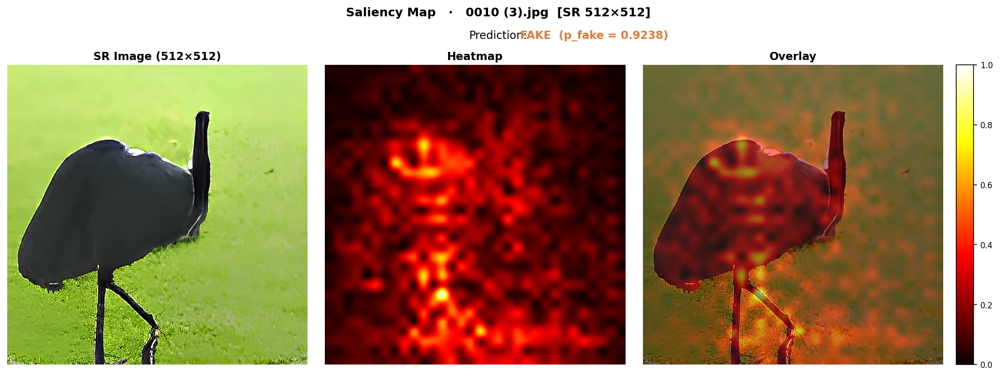

  ✓ Saliency Map done


In [25]:
# =============================================================================
# 1. Saliency Map
# =============================================================================
def _saliency():
    sp = batch["spatial"].clone().requires_grad_(True)

    out = model({**batch, "spatial": sp}).view(-1)
    target = TARGET_SIGN * out[0]

    model.zero_grad()
    target.backward()

    saliency = sp.grad.detach().abs().max(dim=1)[0][0]

    saliency = saliency.cpu().numpy()
    saliency = (saliency - saliency.min()) / (
        saliency.max() - saliency.min() + 1e-8
    )

    _show_panel(
        sr_np,
        _upscale_cam(saliency),
        "Saliency Map",
        prob,
        cmap="hot",
        alpha=0.55
    )

_saliency()

In [26]:
print("  STEP 2 : XAI — Saliency Map + Grad-CAM")

  STEP 2 : XAI — Saliency Map + Grad-CAM
